# Feature-importance sweep: basic parameter-level method

This notebook performs the **main lambda sweep** for the basic gate-matching method.

The training objective is

$$
L = L_{\text{task}} + \lambda_{\text{feat}} L_{\text{feat}},
$$

with

$$
L_{\text{task}} = \frac{1}{N}\sum_{i=1}^N (\hat y_i - y_i)^2
$$

and

$$
L_{\text{feat}} = \frac{1}{d}\sum_{j=1}^d (g_j - z_j)^2.
$$

In [14]:
# Cell 2 - Imports and setup
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import Tensor

from src.models import GatedMLRegressor
from src.training import (
    DEFAULT_TRAIN_CONFIG,
    TrainConfig,
    eval_loader_reg,
    train_gated_feature_importance,
    make_standard_experiment_data,
)
from src.pseudolabels import make_feature_importance_z
from src.alignment import (
    compute_alignment_metrics,
    compute_occlusion_importance,
)

PROJECT_ROOT = Path("..").resolve()
device = "cuda" if torch.cuda.is_available() else "cpu"

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

print("Project root:", PROJECT_ROOT)
print("Using device:", device)

Project root: <project root>
Using device: cuda


In [15]:
# Cell 2a - Execution mode
RUN_TRAINING = False          # True = rerun training/sweep, False = load cached results
RUN_QUALITATIVE = True        # True = allow model-based qualitative plots if checkpoints exist
FORCE_RECOMPUTE_SUMMARIES = False

In [16]:
# Cell 2b - cache loading utilities
from pathlib import Path
import json
import pandas as pd

def read_csv_if_exists(path: Path) -> pd.DataFrame:
    if path.exists():
        return pd.read_csv(path)
    print(f"[Missing] {path}")
    return pd.DataFrame()

def read_json_if_exists(path: Path):
    if path.exists():
        with open(path, "r") as fh:
            return json.load(fh)
    print(f"[Missing] {path}")
    return None

def require_file(path: Path) -> Path:
    assert path.exists(), f"Required file not found: {path}"
    return path

In [17]:
# Cell 3 - Load data and build experiment splits
config = TrainConfig(
    lr=DEFAULT_TRAIN_CONFIG.lr,
    batch_size=DEFAULT_TRAIN_CONFIG.batch_size,
    eval_batch_size=DEFAULT_TRAIN_CONFIG.eval_batch_size,
    num_epochs=60,
    weight_decay=DEFAULT_TRAIN_CONFIG.weight_decay,
    early_stopping_patience=8,
    early_stopping_min_delta=DEFAULT_TRAIN_CONFIG.early_stopping_min_delta,
)

data = make_standard_experiment_data(PROJECT_ROOT, config)

train_loader = data.train_loader
val_loader   = data.val_loader
test_loader  = data.test_loader
feature_cols = data.feature_cols

print("Train/val/test sizes:", len(data.train_df), len(data.val_df), len(data.test_df))
print("Feature columns:", feature_cols)

Train/val/test sizes: 2556 547 549
Feature columns: ['tmin', 'tavg', 'tmax', 'prcp', 'dayofyear_sin', 'dayofyear_cos', 'rand_noise']


## Metrics used in this notebook

### Predictive metrics
- **MSE**: mean squared prediction error.
- **RMSE**: square root of MSE.
- **MAE**: mean absolute error.

### Gate-alignment metrics
These compare the learned gate vector $g$ with the pseudo-label vector $z$.

- **gate_l2**: $|g-z\|_2$, smaller is better.
- **gate_cos**: cosine similarity between $g$ and $z$, larger is better.
- **gate_spearman**: Spearman rank correlation between $g$ and $z$, larger is better.

## Supplementary function-level occlusion analysis

The main regularizer in this notebook acts on the gate vector $g$, which is a parameter-level object.  
To check whether the learned model function also changes in a way that matches the pseudo-label prior, this notebook now computes a supplementary **occlusion-based importance profile**.

For each feature $j$, the occlusion diagnostic:
- sets feature $j$ to its baseline value,
- recomputes predictions,
- measures the average squared prediction change,
- and normalizes the resulting importance vector to sum to 1.

Because the inputs are standardized, the baseline value $0.0$ corresponds to the training-set mean of that feature.

In [18]:
# Cell 5 - Define feature-importance pseudo-label vector z
z_np = make_feature_importance_z(feature_cols).astype(np.float32)
z_t: Tensor = torch.from_numpy(z_np)

print("z:", z_np)

z: [0.7 1.  1.  0.4 0.3 0.3 0. ]


In [19]:
# Cell 6 - Define one sweep run for the basic gate-matching method
def run_feature_importance_experiment(lambda_feat: float, seed: int = 0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = GatedMLRegressor(
        input_dim=len(feature_cols),
        hidden_dims=(64, 64),
        dropout=0.0,
    )
    g_init = model.g.detach().cpu().numpy().copy()

    model, history = train_gated_feature_importance(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        z=z_t,
        lambda_feat=lambda_feat,
        config=config,
        device=device,
        track_gate_history=True,
        gate_names=feature_cols,
    )

    train_metrics = eval_loader_reg(model, train_loader, device=device)
    val_metrics   = eval_loader_reg(model, val_loader,   device=device)
    test_metrics  = eval_loader_reg(model, test_loader,  device=device)

    g_final = model.g.detach().cpu().numpy()
    gate_align = compute_alignment_metrics(g_final, z_np)

    # Supplementary function-level occlusion importance on the test split
    occ_imp = compute_occlusion_importance(
        model=model,
        X=data.X_test,
        device=device,
        batch_size=config.eval_batch_size,
        baseline_value=0.0,
        use_gate=True,
    )

    z_occ = z_np.astype(np.float64).ravel()
    z_occ = z_occ / (z_occ.sum() + 1e-8)
    occ_align = compute_alignment_metrics(occ_imp, z_occ)

    record = {
        "lambda_feat": float(lambda_feat),
        "seed": float(seed),

        "train_mse": train_metrics["mse"],
        "val_mse": val_metrics["mse"],
        "test_mse": test_metrics["mse"],
        "test_rmse": test_metrics["rmse"],
        "test_mae": test_metrics["mae"],

        "gate_l2": gate_align.l2_distance,
        "gate_cos": gate_align.cosine_similarity,
        "gate_spearman": gate_align.spearman_rank_corr,

        "occ_l2": occ_align.l2_distance,
        "occ_cos": occ_align.cosine_similarity,
        "occ_spearman": occ_align.spearman_rank_corr,
    }

    for name, value in zip(feature_cols, g_final):
        record[f"g_final_{name}"] = float(value)

    for name, value in zip(feature_cols, occ_imp):
        record[f"occ_final_{name}"] = float(value)

    hist_df = pd.DataFrame(history)
    hist_df["lambda_feat"] = float(lambda_feat)
    hist_df["seed"] = float(seed)

    init_row = {"epoch": -1.0, "lambda_feat": float(lambda_feat), "seed": float(seed)}
    for name, value in zip(feature_cols, g_init):
        init_row[f"g_{name}"] = float(value)

    hist_df = pd.concat([pd.DataFrame([init_row]), hist_df], ignore_index=True)
    return record, hist_df

In [20]:
# Cell 7 - Run sweep or load cached results
results_dir = PROJECT_ROOT / "results" / "feature_importance_basic" / "sweep_basic"
results_dir.mkdir(parents=True, exist_ok=True)

sweep_df = pd.DataFrame()
history_df = pd.DataFrame()
agg_df = pd.DataFrame()

if RUN_TRAINING:
    lambda_values = [0.0, 1.0, 10, 100.0, 1000.0]
    seeds = [0, 1, 2, 3, 4]

    records = []
    history_frames = []

    for lam in lambda_values:
        for seed in seeds:
            print(f"Running: lambda_feat={lam}, seed={seed}")
            rec, hist = run_feature_importance_experiment(lambda_feat=lam, seed=seed)
            records.append(rec)
            history_frames.append(hist)

    sweep_df = pd.DataFrame(records)
    history_df = pd.concat(history_frames, ignore_index=True)

    agg_spec = {
        "test_mse_mean": ("test_mse", "mean"),
        "test_rmse_mean": ("test_rmse", "mean"),
        "test_rmse_std": ("test_rmse", "std"),
        "test_mae_mean": ("test_mae", "mean"),
        "gate_l2_mean": ("gate_l2", "mean"),
        "gate_l2_std": ("gate_l2", "std"),
        "gate_cosine_mean": ("gate_cos", "mean"),
        "gate_cosine_std": ("gate_cos", "std"),
        "gate_spearman_mean": ("gate_spearman", "mean"),
        "gate_spearman_std": ("gate_spearman", "std"),
        "occ_l2_mean": ("occ_l2", "mean"),
        "occ_l2_std": ("occ_l2", "std"),
        "occ_cosine_mean": ("occ_cos", "mean"),
        "occ_cosine_std": ("occ_cos", "std"),
        "occ_spearman_mean": ("occ_spearman", "mean"),
        "occ_spearman_std": ("occ_spearman", "std"),
    }

    for name in feature_cols:
        agg_spec[f"g_final_{name}_mean"] = (f"g_final_{name}", "mean")
        agg_spec[f"g_final_{name}_std"] = (f"g_final_{name}", "std")
        agg_spec[f"occ_final_{name}_mean"] = (f"occ_final_{name}", "mean")
        agg_spec[f"occ_final_{name}_std"] = (f"occ_final_{name}", "std")

    agg_df = sweep_df.groupby("lambda_feat").agg(**agg_spec).reset_index()

else:
    sweep_df = pd.read_csv(results_dir / "runs_raw.csv")
    history_df = pd.read_csv(results_dir / "history_raw.csv")
    agg_df = pd.read_csv(results_dir / "sweep_summary.csv")

In [21]:
display(sweep_df)

,lambda_feat,seed,train_mse,val_mse,test_mse,test_rmse,test_mae,gate_l2,gate_cos,gate_spearman,occ_l2,occ_cos,occ_spearman,g_final_tmin,g_final_tavg,g_final_tmax,g_final_prcp,g_final_dayofyear_sin,g_final_dayofyear_cos,g_final_rand_noise,occ_final_tmin,occ_final_tavg,occ_final_tmax,occ_final_prcp,occ_final_dayofyear_sin,occ_final_dayofyear_cos,occ_final_rand_noise
0,0.0,0.0,5.550548,6.021366,5.423264,2.328790,1.831475,1.094293,0.836110,0.527360,0.302588,0.857762,0.709208,0.749635,0.765756,0.755712,0.765638,0.750333,0.760105,0.729574,0.003473,0.400451,0.368027,0.011106,0.008571,0.207164,0.001209
1,0.0,1.0,5.494582,6.029411,5.420974,2.328299,1.830728,1.090670,0.836262,0.636469,0.373259,0.807620,0.691023,0.753854,0.761890,0.755171,0.748877,0.752805,0.758905,0.729850,0.011892,0.555051,0.225379,0.008954,0.014368,0.183499,0.000857
2,0.0,2.0,5.577084,6.024883,5.381328,2.319769,1.817485,1.090855,0.835751,0.509175,0.304017,0.851546,0.654654,0.747011,0.762953,0.753695,0.750395,0.752232,0.756943,0.731306,0.009474,0.449770,0.293416,0.011536,0.029776,0.205232,0.000796
3,0.0,3.0,5.438908,6.040339,5.338117,2.310437,1.815616,1.093148,0.836225,0.381881,0.319500,0.838209,0.654654,0.740020,0.773309,0.751941,0.766341,0.752422,0.761283,0.727171,0.009679,0.477175,0.261091,0.011288,0.034583,0.205280,0.000904
4,0.0,4.0,5.442359,6.030508,5.299852,2.302141,1.805719,1.096136,0.834797,0.436436,0.344706,0.833231,0.781947,0.747953,0.768663,0.753033,0.738348,0.751034,0.765278,0.741828,0.015044,0.528724,0.264083,0.009344,0.014371,0.167417,0.001018
5,1.0,0.0,5.554441,6.021420,5.417645,2.327584,1.831244,1.035931,0.848321,0.836502,0.302549,0.858026,0.709208,0.748164,0.769469,0.758262,0.742719,0.726406,0.749899,0.676435,0.003640,0.399832,0.369590,0.010820,0.008454,0.206445,0.001219
6,1.0,1.0,5.502493,6.011937,5.418995,2.327873,1.830324,1.049336,0.844936,0.872872,0.372265,0.808001,0.691023,0.752672,0.765099,0.757968,0.728714,0.736600,0.751299,0.694428,0.012118,0.553364,0.225548,0.008819,0.014419,0.184917,0.000814
7,1.0,2.0,5.500286,5.990580,5.379710,2.319420,1.793194,0.989455,0.858152,0.836502,0.382102,0.798685,0.781947,0.746071,0.773592,0.755438,0.725085,0.718608,0.747283,0.620364,0.026214,0.572262,0.191787,0.011738,0.020638,0.176692,0.000671
8,1.0,3.0,5.414952,6.031912,5.276947,2.297161,1.799322,0.971361,0.862888,0.836502,0.349329,0.818353,0.691023,0.738152,0.781251,0.756583,0.730428,0.726526,0.748046,0.585774,0.014188,0.526252,0.223626,0.011031,0.033328,0.190614,0.000960
9,1.0,4.0,5.446246,6.021483,5.298934,2.301941,1.803933,1.022893,0.850791,0.781947,0.346982,0.832283,0.781947,0.747219,0.774249,0.757028,0.718002,0.725930,0.752211,0.668614,0.015828,0.532854,0.262481,0.009081,0.013993,0.164887,0.000875


In [22]:
# Cell 8 - Save raw run-level and history-level sweep outputs
if RUN_TRAINING:
    sweep_df.to_csv(results_dir / "runs_raw.csv", index=False)
    history_df.to_csv(results_dir / "history_raw.csv", index=False)
    agg_df.to_csv(results_dir / "sweep_summary.csv", index=False)
    print("Saved raw sweep results and summary to:", results_dir)
else:
    print("RUN_TRAINING=False, so no files were written.")

RUN_TRAINING=False, so no files were written.


In [23]:
# Cell 9 - Aggregate the sweep results, including supplementary occlusion metrics
# Display the aggregated summary table
display(agg_df.round(4))

,lambda_feat,test_mse_mean,test_rmse_mean,test_rmse_std,test_mae_mean,gate_l2_mean,gate_l2_std,gate_cosine_mean,gate_cosine_std,gate_spearman_mean,gate_spearman_std,occ_l2_mean,occ_l2_std,occ_cosine_mean,occ_cosine_std,occ_spearman_mean,occ_spearman_std,g_final_tmin_mean,g_final_tmin_std,occ_final_tmin_mean,occ_final_tmin_std,g_final_tavg_mean,g_final_tavg_std,occ_final_tavg_mean,occ_final_tavg_std,g_final_tmax_mean,g_final_tmax_std,occ_final_tmax_mean,occ_final_tmax_std,g_final_prcp_mean,g_final_prcp_std,occ_final_prcp_mean,occ_final_prcp_std,g_final_dayofyear_sin_mean,g_final_dayofyear_sin_std,occ_final_dayofyear_sin_mean,occ_final_dayofyear_sin_std,g_final_dayofyear_cos_mean,g_final_dayofyear_cos_std,occ_final_dayofyear_cos_mean,occ_final_dayofyear_cos_std,g_final_rand_noise_mean,g_final_rand_noise_std,occ_final_rand_noise_mean,occ_final_rand_noise_std
0,0.0,5.3727,2.3179,0.0116,1.8202,1.0930,0.0023,0.8358,0.0006,0.4983,0.0967,0.3288,0.0301,0.8377,0.0195,0.6983,0.0524,0.7477,0.0050,0.0099,0.0042,0.7665,0.0046,0.4822,0.0617,0.7539,0.0015,0.2824,0.0536,0.7539,0.0120,0.0104,0.0012,0.7518,0.0010,0.0203,0.0112,0.7605,0.0031,0.1937,0.0176,0.7319,0.0057,0.0010,0.0002
1,1.0,5.3584,2.3148,0.0144,1.8116,1.0138,0.0325,0.8530,0.0074,0.8329,0.0325,0.3506,0.0308,0.8231,0.0232,0.7310,0.0471,0.7465,0.0053,0.0144,0.0081,0.7727,0.0060,0.5169,0.0679,0.7571,0.0011,0.2546,0.0690,0.7290,0.0090,0.0103,0.0013,0.7268,0.0064,0.0182,0.0095,0.7497,0.0021,0.1847,0.0155,0.6491,0.0448,0.0009,0.0002
2,10.0,5.2979,2.3017,0.0147,1.8053,0.5653,0.0105,0.9434,0.0018,0.9165,0.0244,0.4370,0.0558,0.7697,0.0368,0.7856,0.0595,0.7313,0.0044,0.0272,0.0086,0.8151,0.0056,0.6343,0.0574,0.8008,0.0054,0.1697,0.0482,0.5176,0.0107,0.0083,0.0005,0.4836,0.0294,0.0097,0.0064,0.6099,0.0157,0.1503,0.0130,0.3162,0.0148,0.0004,0.0001
3,100.0,5.2677,2.2951,0.0130,1.8014,0.3161,0.0026,0.9825,0.0003,0.9820,0.0000,0.5026,0.0504,0.7329,0.0321,0.7783,0.0797,0.7012,0.0006,0.0339,0.0073,0.9011,0.0028,0.7056,0.0464,0.8968,0.0042,0.1283,0.0405,0.4161,0.0017,0.0071,0.0002,0.3452,0.0015,0.0038,0.0020,0.3633,0.0046,0.1209,0.0088,0.2705,0.0024,0.0004,0.0001
4,1000.0,5.2422,2.2895,0.0164,1.7961,0.3013,0.0001,0.9839,0.0000,0.9820,0.0000,0.5083,0.0502,0.7295,0.0318,0.7783,0.0797,0.7000,0.0002,0.0355,0.0065,0.9186,0.0002,0.7111,0.0458,0.9180,0.0004,0.1233,0.0401,0.4108,0.0001,0.0071,0.0004,0.3467,0.0001,0.0034,0.0017,0.3466,0.0002,0.1192,0.0083,0.2702,0.0001,0.0004,0.0001


## Main sweep summary with supplementary occlusion alignment

The next figure extends the original main sweep summary with a third panel for **occlusion cosine similarity**.

This makes it possible to compare:
- predictive performance,
- parameter-level gate alignment,
- and function-level occlusion alignment

within the same $\lambda_{\text{feat}}$ sweep.

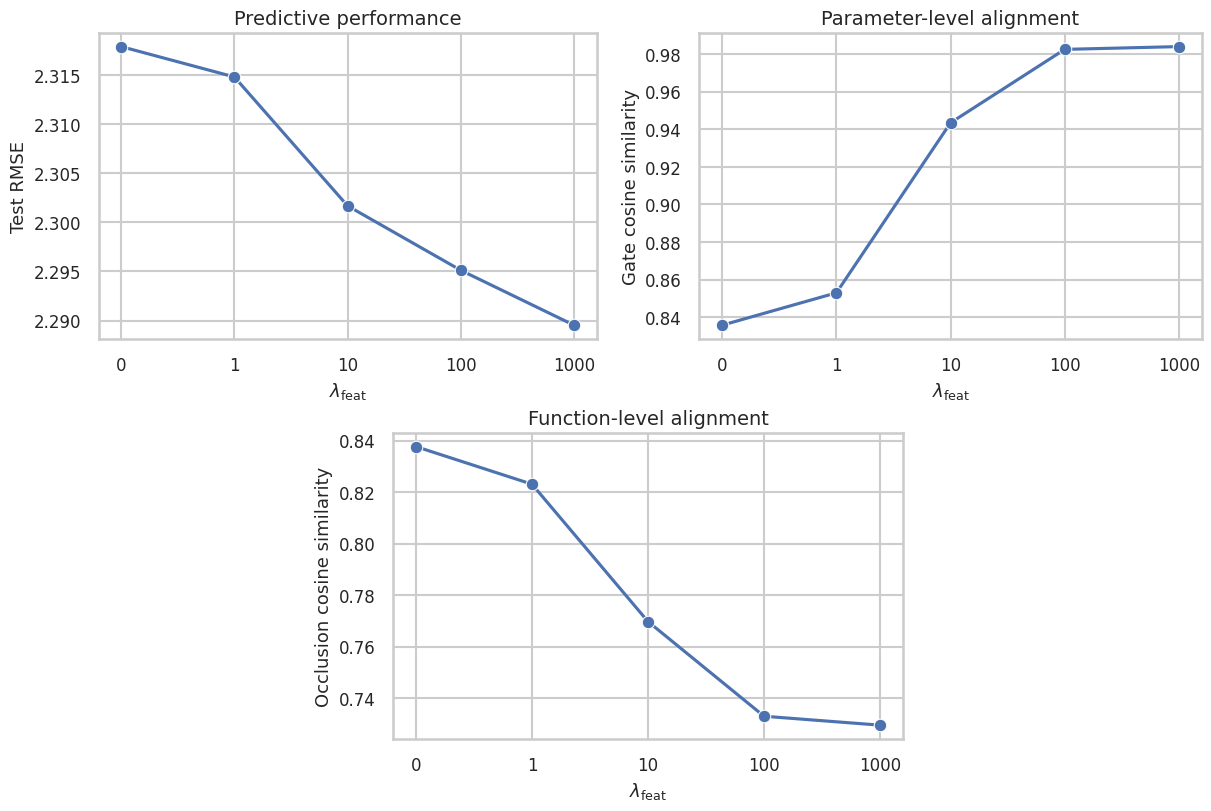

In [24]:
# Cell 10 - Plot predictive performance, gate alignment, and occlusion alignment across lambda
plot_df = agg_df.copy()
plot_df["lambda_label"] = plot_df["lambda_feat"].map(lambda x: f"{x:g}")

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

fig = plt.figure(figsize=(12, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 4)

ax1 = fig.add_subplot(gs[0, 0:2])  # top left
ax2 = fig.add_subplot(gs[0, 2:4])  # top right
ax3 = fig.add_subplot(gs[1, 1:3])  # bottom centered, same width

sns.lineplot(data=plot_df, x="lambda_label", y="test_rmse_mean", marker="o", ax=ax1)
ax1.set_xlabel(r"$\lambda_{\mathrm{feat}}$")
ax1.set_ylabel("Test RMSE")
ax1.set_title("Predictive performance")

sns.lineplot(data=plot_df, x="lambda_label", y="gate_cosine_mean", marker="o", ax=ax2)
ax2.set_xlabel(r"$\lambda_{\mathrm{feat}}$")
ax2.set_ylabel("Gate cosine similarity")
ax2.set_title("Parameter-level alignment")

sns.lineplot(data=plot_df, x="lambda_label", y="occ_cosine_mean", marker="o", ax=ax3)
ax3.set_xlabel(r"$\lambda_{\mathrm{feat}}$")
ax3.set_ylabel("Occlusion cosine similarity")
ax3.set_title("Function-level alignment")

for ax in [ax1, ax2, ax3]:
    ax.tick_params(labelsize=12)

fig.savefig("../docs/figures/ch5_feat_lambda_main.pdf", bbox_inches="tight")
plt.show()

In [25]:
# Cell 10a - Table version of the main sweep-summary plots
sweep_plot_table = agg_df[
    [
        "lambda_feat",
        "test_mse_mean",
        "test_rmse_mean",
        "test_mae_mean",
        "gate_l2_mean",
        "gate_cosine_mean",
        "gate_spearman_mean",
        "occ_l2_mean",
        "occ_cosine_mean",
        "occ_spearman_mean",
    ]
].round(4)

display(sweep_plot_table)

,lambda_feat,test_mse_mean,test_rmse_mean,test_mae_mean,gate_l2_mean,gate_cosine_mean,gate_spearman_mean,occ_l2_mean,occ_cosine_mean,occ_spearman_mean
0,0.0,5.3727,2.3179,1.8202,1.0930,0.8358,0.4983,0.3288,0.8377,0.6983
1,1.0,5.3584,2.3148,1.8116,1.0138,0.8530,0.8329,0.3506,0.8231,0.7310
2,10.0,5.2979,2.3017,1.8053,0.5653,0.9434,0.9165,0.4370,0.7697,0.7856
3,100.0,5.2677,2.2951,1.8014,0.3161,0.9825,0.9820,0.5026,0.7329,0.7783
4,1000.0,5.2422,2.2895,1.7961,0.3013,0.9839,0.9820,0.5083,0.7295,0.7783


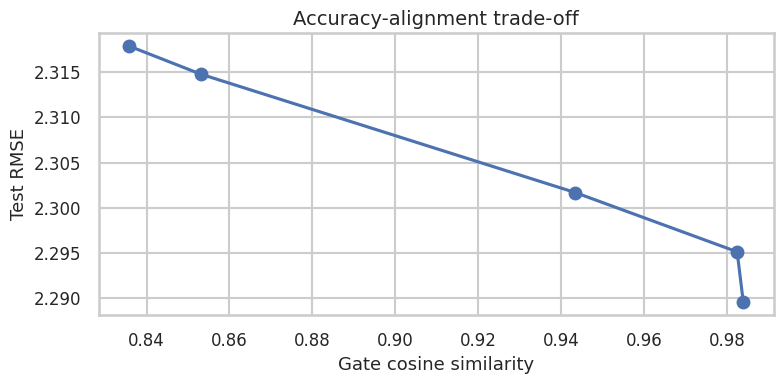

In [26]:
# Cell 11 - Plot the predictive-accuracy versus gate-alignment trade-off
plt.figure(figsize=(8, 4))
plt.plot(agg_df["gate_cosine_mean"], agg_df["test_rmse_mean"], marker="o")
plt.xlabel("Gate cosine similarity")
plt.ylabel("Test RMSE")
plt.title("Accuracy-alignment trade-off")
plt.tight_layout()
plt.savefig("../docs/figures/ch5_feat_tradeoff.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../docs/figures/ch5_feat_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
# Cell 11a - Table version of the accuracy-alignment trade-off plot
tradeoff_table = agg_df[
    ["lambda_feat", "gate_cosine_mean", "test_rmse_mean"]
].round(4)

tradeoff_table

,lambda_feat,gate_cosine_mean,test_rmse_mean
0,0.0,0.8358,2.3179
1,1.0,0.8530,2.3148
2,10.0,0.9434,2.3017
3,100.0,0.9825,2.2951
4,1000.0,0.9839,2.2895


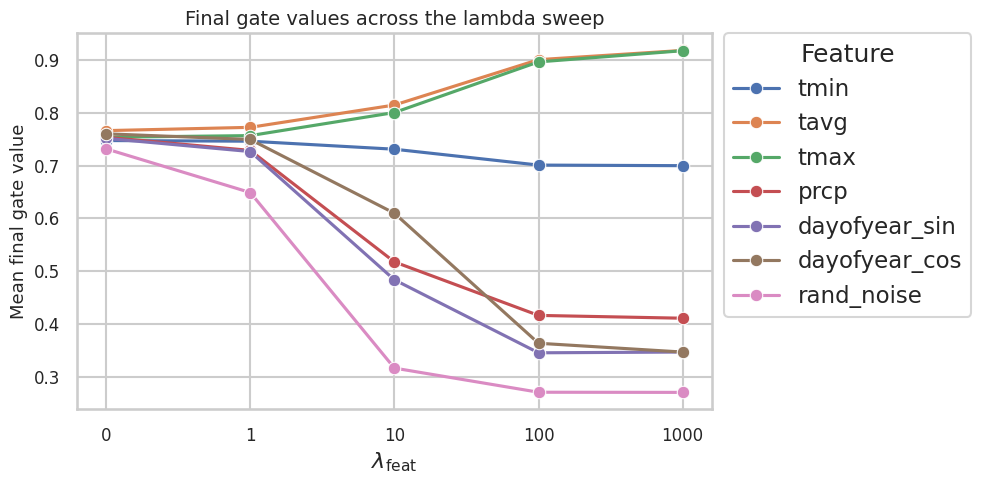

In [28]:
# Cell 12 - Plot mean final gate values across the lambda sweep
g_long_rows = []
for _, row in agg_df.iterrows():
    lam = row["lambda_feat"]
    for name in feature_cols:
        g_long_rows.append(
            {
                "lambda_feat": lam,
                "feature": name,
                "g_final_mean": row[f"g_final_{name}_mean"],
            }
        )
g_long_df = pd.DataFrame(g_long_rows)

g_long_df["lambda_label"] = g_long_df["lambda_feat"].map(lambda x: f"{x:g}")

plt.figure(figsize=(10, 5))
ax = sns.lineplot(
    data=g_long_df,
    x="lambda_label",
    y="g_final_mean",
    hue="feature",
    marker="o"
)

ax.set_xlabel(r"$\lambda_{\mathrm{feat}}$", fontsize=16)
ax.set_ylabel("Mean final gate value")
ax.set_title("Final gate values across the lambda sweep")

ax.legend(
    title="Feature",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
)

plt.tight_layout()
plt.savefig("../docs/figures/ch5_feat_gate_means.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
# Cell 12a - Table version of the mean-final-gate plot
gate_mean_table = g_long_df.pivot(
    index="lambda_feat",
    columns="feature",
    values="g_final_mean",
).round(4)

gate_mean_table

feature,dayofyear_cos,dayofyear_sin,prcp,rand_noise,tavg,tmax,tmin
lambda_feat,,,,,,,
0.0,0.7605,0.7518,0.7539,0.7319,0.7665,0.7539,0.7477
1.0,0.7497,0.7268,0.7290,0.6491,0.7727,0.7571,0.7465
10.0,0.6099,0.4836,0.5176,0.3162,0.8151,0.8008,0.7313
100.0,0.3633,0.3452,0.4161,0.2705,0.9011,0.8968,0.7012
1000.0,0.3466,0.3467,0.4108,0.2702,0.9186,0.9180,0.7000


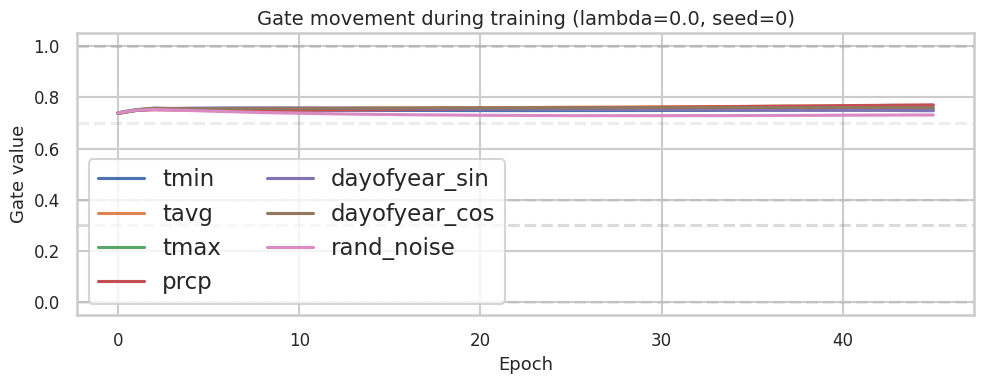

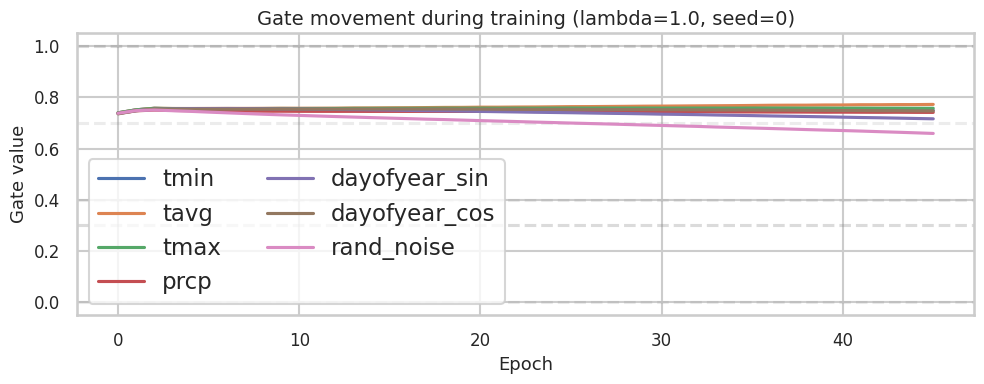

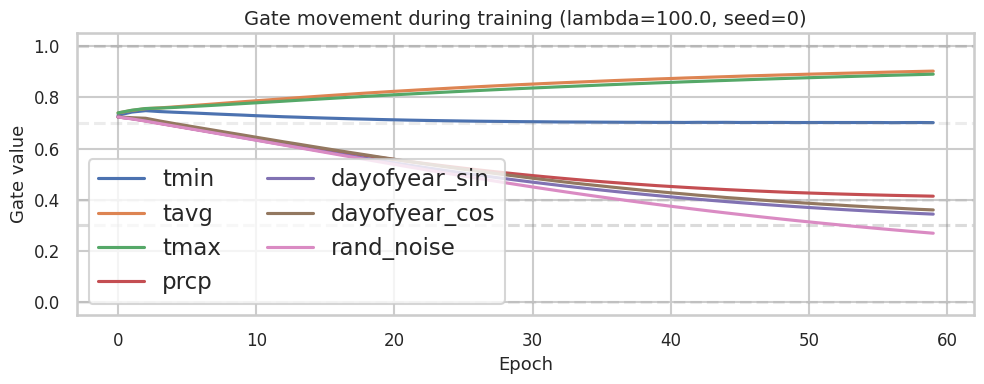

In [30]:
# Cell 13 - Plot gate trajectories for selected lambda values
selected_lambdas = [0.0, 1.0, 100.0]
selected_seed = 0

traj_df = history_df[
    (history_df["lambda_feat"].isin(selected_lambdas)) &
    (history_df["seed"] == selected_seed) &
    (history_df["epoch"] >= 0)
].copy()

for lam in selected_lambdas:
    sub = traj_df[traj_df["lambda_feat"] == lam]
    plt.figure(figsize=(10, 4))
    for name, z_val in zip(feature_cols, z_np):
        plt.plot(sub["epoch"], sub[f"g_{name}"], label=name)
        plt.axhline(z_val, linestyle="--", alpha=0.15, color="gray")
    plt.title(f"Gate movement during training (lambda={lam}, seed={selected_seed})")
    plt.xlabel("Epoch")
    plt.ylabel("Gate value")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

In [31]:
# Cell 13a - Table version of the selected gate-trajectory plots
selected_lambdas = [0.0, 1.0, 100.0]
selected_seed = 0
selected_features_for_traj = ["tmin", "tavg", "tmax", "prcp", "rand_noise"]

def gate_cos_to_z_from_row(row, feature_names, z_vec):
    g = np.array([row[f"g_{name}"] for name in feature_names], dtype=float)
    denom = np.linalg.norm(g) * np.linalg.norm(z_vec)
    if denom == 0:
        return np.nan
    return float(np.dot(g, z_vec) / denom)

traj_summary_frames = []

for lam in selected_lambdas:
    sub = history_df[
        (history_df["lambda_feat"] == float(lam)) &
        (history_df["seed"] == float(selected_seed))
    ].copy()

    milestone_epochs = sorted(set([-1, 0, 1, 2, 5, 10, 20, int(sub["epoch"].max())]))
    sub = sub[sub["epoch"].isin(milestone_epochs)].copy()

    sub["gate_l2_to_z"] = sub.apply(
        lambda r: float(
            np.linalg.norm(
                np.array([r[f"g_{name}"] for name in feature_cols], dtype=float) - z_np.astype(float)
            )
        ),
        axis=1,
    )

    sub["gate_cos_to_z"] = sub.apply(
        lambda r: gate_cos_to_z_from_row(r, feature_cols, z_np.astype(float)),
        axis=1,
    )

    keep_cols = (
        ["lambda_feat", "seed", "epoch", "gate_l2_to_z", "gate_cos_to_z"]
        + [f"g_{name}" for name in selected_features_for_traj]
    )

    traj_summary_frames.append(
        sub[keep_cols].sort_values("epoch")
    )

traj_milestone_table = pd.concat(traj_summary_frames, ignore_index=True).round(4)

display(traj_milestone_table)

,lambda_feat,seed,epoch,gate_l2_to_z,gate_cos_to_z,g_tmin,g_tavg,g_tmax,g_prcp,g_rand_noise
0,0.0,0.0,-1.0,1.0776,0.8313,0.7311,0.7311,0.7311,0.7311,0.7311
1,0.0,0.0,0.0,1.0870,0.8317,0.7395,0.7397,0.7398,0.7385,0.7397
2,0.0,0.0,1.0,1.1020,0.8319,0.7515,0.7514,0.7513,0.7488,0.7500
3,0.0,0.0,2.0,1.1073,0.8325,0.7572,0.7575,0.7571,0.7518,0.7525
4,0.0,0.0,5.0,1.1040,0.8329,0.7541,0.7566,0.7560,0.7496,0.7464
5,0.0,0.0,10.0,1.0989,0.8339,0.7508,0.7568,0.7560,0.7501,0.7380
6,0.0,0.0,20.0,1.0936,0.8355,0.7485,0.7599,0.7570,0.7551,0.7301
7,0.0,0.0,45.0,1.0961,0.8360,0.7513,0.7680,0.7541,0.7708,0.7312
8,1.0,0.0,-1.0,1.0776,0.8313,0.7311,0.7311,0.7311,0.7311,0.7311
9,1.0,0.0,0.0,1.0844,0.8322,0.7395,0.7397,0.7398,0.7371,0.7380


In [32]:
# Cell 14 - Display a compact sweep summary table including occlusion alignment
display(
    agg_df[
        [
            "lambda_feat",
            "test_rmse_mean",
            "test_rmse_std",
            "gate_l2_mean",
            "gate_cosine_mean",
            "gate_spearman_mean",
            "occ_l2_mean",
            "occ_cosine_mean",
            "occ_spearman_mean",
        ]
    ].round(4)
)

,lambda_feat,test_rmse_mean,test_rmse_std,gate_l2_mean,gate_cosine_mean,gate_spearman_mean,occ_l2_mean,occ_cosine_mean,occ_spearman_mean
0,0.0,2.3179,0.0116,1.0930,0.8358,0.4983,0.3288,0.8377,0.6983
1,1.0,2.3148,0.0144,1.0138,0.8530,0.8329,0.3506,0.8231,0.7310
2,10.0,2.3017,0.0147,0.5653,0.9434,0.9165,0.4370,0.7697,0.7856
3,100.0,2.2951,0.0130,0.3161,0.9825,0.9820,0.5026,0.7329,0.7783
4,1000.0,2.2895,0.0164,0.3013,0.9839,0.9820,0.5083,0.7295,0.7783
